# YAML multilayer workflow — demo

This notebook walks through the new workflow end to end:

**stack spec → search (tournament tree) → `index.csv` → `find` → `lineage` → write a VASP file**

Every structure the search finds (monolayer roots, bilayers, trilayers, …) is saved as a
small YAML *recipe* — metadata only, no atoms. The atoms are rebuilt on demand from the
primitive POSCARs by following the recipe's `parents` back to the roots.

The notebook lives in `dev/`, while all paths in the spec are relative to the repository
root, so we pass `base_dir=".."` where needed.

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # silence match.py's progress bars in this notebook

from pathlib import Path
import yaml
import numpy as np

from MLM.spec import load_stack_spec, run_stack_spec
from MLM.index import load_index, find, get, lineage
from MLM.build import write_structure, build_atoms

REPO = Path("..")

## 1. The stack spec (the job)

A stack spec lists the layers bottom-up (POSCAR + material label), the search parameters
(a `default` block plus overrides per round) and the filters. This one is the BTO trilayer
of `notebooks/trilayer_candidate_finder.ipynb`, with narrow angle windows so it runs in seconds.

In [2]:
spec_path = REPO / "examples" / "bto_trilayer_demo.yaml"
print(spec_path.read_text())

# Stack spec: BTO homo-trilayer, the case of notebooks/trilayer_candidate_finder.ipynb.
# Run from the repository root:
#     python -c "from MLM.spec import run_stack_spec; print(run_stack_spec('examples/bto_trilayer_demo.yaml').summary())"
#
# Every twist is measured from the layer directly below (layer 3 vs layer 2 here).
# The angle windows are narrow (a few degrees) so the demo finishes in seconds.
# For a full landscape scan use degmin 1, degmax 45 in round 1 and degmin 1,
# degmax 60.01 in round 2 (the notebook settings) — ~3 minutes per bilayer candidate.
name: bto_trilayer_demo
output_dir: runs/bto_trilayer_demo
layers:
  - {poscar: moire_structures/bto/bto_1-layer.vasp, material: bto}
  - {poscar: moire_structures/bto/bto_1-layer.vasp, material: bto}
  - {poscar: moire_structures/bto/bto_1-layer.vasp, material: bto}
search:
  default: {degmin: 20.0, degmax: 24.0, degstep: 0.01, dtol: 5.0e-4, nmin: -10, nmax: 10, goodangles: [90.0]}
  rounds:
    2: {degmin: 35.0, degmax: 38.0

In [3]:
spec = load_stack_spec(spec_path)
for number in (1, 2):
    print(f"round {number}:", spec.schedule.params_for_round(number))

round 1: SearchParams(degmin=20.0, degmax=24.0, degstep=0.01, dtol=0.0005, nmin=-10, nmax=10, goodangles=(90.0,), dedupe=True, keep_supercells=False, angle_cluster_tol=None, strain_mode='isotropic', strain_residual_tol=1e-06, scanner='fast', merge_equivalent_twists='none', include_axes=False, max_matches_per_angle='auto')
round 2: SearchParams(degmin=35.0, degmax=38.0, degstep=0.01, dtol=0.0005, nmin=-40, nmax=40, goodangles=(90.0,), dedupe=True, keep_supercells=False, angle_cluster_tol=None, strain_mode='isotropic', strain_residual_tol=1e-06, scanner='fast', merge_equivalent_twists='none', include_axes=False, max_matches_per_angle='auto')


## 2. Dry run: what will be searched?

Three layers need two rounds: (L1 + L2) first while L3 is carried forward, then
(bilayer + L3). In round 2 the number of searches is (number of bilayer candidates) × 1,
which is only known after round 1 — the dry run says so instead of guessing.

In [4]:
plan = run_stack_spec(spec_path, base_dir=REPO, dry_run=True)

DRY RUN — nothing searched
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: ? x 1 = ? searches (known once the previous round has run)


## 3. Run it

One call: builds the roots, runs both rounds, writes every candidate's YAML and the index.

In [5]:
result = run_stack_spec(spec_path, base_dir=REPO, log=None)   # log=print shows progress live
run_dir = result.run_dir
print(result.summary())

run directory: ../runs/bto_trilayer_demo
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 1 x 1 = 1 searches -> 3 candidates, 2 passed filters (0.6 s)
full-stack candidates passing filters: 2


In [6]:
sorted(p.name for p in (run_dir / "yamls").glob("*.yaml"))

['bto_1_406932.yaml',
 'bto_2_22.62_1fdb6f.yaml',
 'bto_3_22.62_35.30_4f0401.yaml',
 'bto_3_22.62_35.49_fbb78b.yaml',
 'bto_3_22.62_36.87_015688.yaml']

## 4. The index table

`index.csv` has one row per recipe with all scalar fields, so we can filter without opening
any YAML file. `passed_filter` says whether the candidate went on to the next round
(rejected candidates are kept on disk too).

In [7]:
table = load_index(run_dir)
table[["id", "n_layers", "twist", "residual", "cumulative_residual", "max_layer_residual",
       "cell_area", "round", "passed_filter"]]

,id,n_layers,twist,residual,cumulative_residual,max_layer_residual,cell_area,round,passed_filter
0,bto_1_406932,1,NaN,NaN,NaN,NaN,15.923125,0,True
1,bto_2_22.62_1fdb6f,2,22.62,0.000034,0.000034,0.000034,207.000629,1,True
2,bto_3_22.62_35.30_4f0401,3,35.30,0.000657,0.000657,0.000783,110331.335360,2,True
3,bto_3_22.62_35.49_fbb78b,3,35.49,0.001447,0.001447,0.001447,10971.033347,2,False
4,bto_3_22.62_36.87_015688,3,36.87,0.000133,0.000133,0.000133,1035.003146,2,True


## 5. Jump to a structure with `find` and `get`

`find` filters the index (here: trilayers with a small cumulative residual), `get` loads the
full recipe of one id as a `MoireStructure`.

In [8]:
trilayers = find(run_dir, n_layers=3, max_cumulative_residual=1e-3, material="bto")
trilayers[["id", "twist", "cumulative_residual", "cell_area"]]

,id,twist,cumulative_residual,cell_area
4,bto_3_22.62_36.87_015688,36.87,0.000133,1035.003146
2,bto_3_22.62_35.30_4f0401,35.30,0.000657,110331.335360


In [9]:
best_id = trilayers["id"].iloc[0]
trilayer = get(run_dir, best_id)
print(trilayer)
print("absolute layer rotations (deg):", np.round(trilayer.layer_rotations, 4))
print("moiré lattice vectors (Å):\n", trilayer.lattice_vectors.round(4))

MoireStructure(id='bto_3_22.62_36.87_015688', n_layers=3, twist=36.8700)
absolute layer rotations (deg): [ 0.   22.62 59.49]
moiré lattice vectors (Å):
 [[-27.9327 -15.9615]
 [ 15.9615 -27.9327]]


This is the recipe file itself — note `parents` (ids, not copies). Every `twist` is
measured from the layer directly below: the trilayer's `twist` (36.87°) is layer 3 relative
to layer 2, and `layer_rotations` gives the absolute angles (0, 22.62, 22.62 + 36.87 = 59.49°).

In [10]:
print((run_dir / "yamls" / f"{best_id}.yaml").read_text())

id: bto_3_22.62_36.87_015688
level: 2
n_layers: 3
material: [bto, bto, bto]
parents: [bto_2_22.62_1fdb6f, bto_1_406932]
twist: 36.86999999999963
lattice_vectors:
- [-27.932653665700002, -15.961516380400003]
- [15.961516380400003, -27.932653665700002]
angle_between_vectors: 90.0
residual: 0.00013330305566522737
cumulative_residual: 0.00013330305566522737
source_poscar: [moire_structures/bto/bto_1-layer.vasp, moire_structures/bto/bto_1-layer.vasp,
  moire_structures/bto/bto_1-layer.vasp]
units: angstrom
twist_sequence: [22.62000000000041, 36.86999999999963]
layer_rotations: [0.0, 22.62000000000041, 59.49000000000004]
layer_residuals: [1.7763568394002505e-15, 7.583140347793097e-05, 0.00013330305566522737]
coefficients:
  lower:
  - [1, 2]
  - [-2, 1]
  upper:
  - [-7, 4]
  - [-4, -7]
layer_strains:
- - [0.0, 0.0]
  - [0.0, 0.0]
- - [0.0, 0.0]
  - [0.0, 0.0]
- - [0.0, 0.0]
  - [0.0, 0.0]
strain_energy: null
schema_version: 3



## 6. Lineage

Following `parents` back to the level-0 roots. The same root appears three times because all
three layers come from the same POSCAR (identical recipe → identical id).

In [11]:
tree = lineage(run_dir, best_id)
print(tree)

bto_3_22.62_36.87_015688  (3 layers)  twist=36.8700  residual=1.33e-04
    bto_2_22.62_1fdb6f  (2 layers)  twist=22.6200  residual=3.39e-05
        bto_1_406932  (1 layer)
        bto_1_406932  (1 layer)
    bto_1_406932  (1 layer)


## 7. Rebuild the atoms and write a VASP file

`write_structure` walks the lineage, rotates and stacks each primitive layer, folds the atoms
into the moiré cell and writes the file with ASE. The atom count per layer is checked against
(cell area / primitive area) × atoms per primitive cell.

In [12]:
vasp_path = write_structure(run_dir, best_id, fmt="vasp")
lammps_path = write_structure(run_dir, best_id, fmt="lammps")
print(vasp_path)
print(lammps_path)
print("".join(vasp_path.read_text().splitlines(keepends=True)[:8]))

../runs/bto_trilayer_demo/structures/bto_3_22.62_36.87_015688.vasp
../runs/bto_trilayer_demo/structures/bto_3_22.62_36.87_015688.data
Ba O  Ti
 1.0000000000000000
   -27.9326536657000020  -15.9615163804000026    0.0000000000000000
    15.9615163804000026  -27.9326536657000020    0.0000000000000000
     0.0000000000000000    0.0000000000000000   74.6205278874000015
 Ba  O   Ti 
 390 780 195
Cartesian



In [13]:
built = build_atoms(trilayer, search_dirs=[REPO])
print("atoms per layer:", built.layer_counts, " expected:", built.expected_counts)
print("composition:", built.composition)

atoms per layer: [455, 455, 455]  expected: [455, 455, 455]
composition: {'Ba': 390, 'O': 780, 'Ti': 195}


A top view of the cell, one colour per layer (only Ti atoms, to keep it readable):

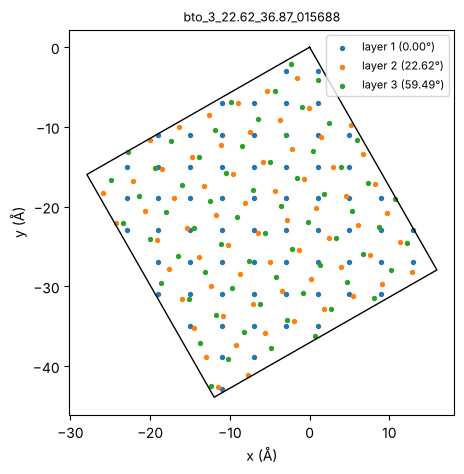

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ti = built.atoms[built.atoms["type"] == "Ti"]
for layer, group in ti.groupby("layer"):
    angle = trilayer.layer_rotations[layer]
    ax.scatter(group["x"], group["y"], s=8, label=f"layer {layer + 1} ({angle:.2f}°)")
a1, a2 = trilayer.lattice_vectors
corners = np.array([[0, 0], a1, a1 + a2, a2, [0, 0]])
ax.plot(corners[:, 0], corners[:, 1], "k-", lw=1)
ax.set_aspect("equal"); ax.set_xlabel("x (Å)"); ax.set_ylabel("y (Å)")
ax.legend(loc="upper right", fontsize=8)
ax.set_title(best_id, fontsize=9)
plt.show()

## Where to go from here

- Widen the windows in the spec (round 1: `degmin: 1, degmax: 45`; round 2: `degmin: 1,
  degmax: 60.01`) to scan the whole landscape like the notebooks did. Because twists are
  measured from the layer below, round 2's 1–60.01° is the notebook's θ+1 … θ+60.01 window.
- `find(run_dir, ...)` accepts more filters: `angle_between_vectors`, `twist_range`,
  `max_cell_area`, `max_layer_residual`, `passed_filter`.
- See `docs/IMPLEMENTATION_NOTES.md` for the full API.